# AI 500 – Foundations of AI
## Programming Assignment 3: Classification, Model Behaviour & Imbalance

**Name:**

**Roll Number:**

This notebook has two tasks:

- **Task 1:** Classification Models and Behaviour
- **Task 2:** Multiclass Classification & Class Imbalance



Before you start, an important clarification , this notebook has two kinds of work that contribute evidence to the graded report:

- <span style="color: purple; font-size: 20px;">**Tasks**</span> (purple) require hands-on coding, implementation, or a small calculation.
- <span style="color: green; font-size: 20px;">**Questions**</span> (green) require written, analytical answers, interpret your results instead of just restating them.

**You must attempt both.** Where a task has an accompanying question, complete both for full credit.

**Notes:**
- Keep the supplied dataset and split variables unchanged, and retain named results needed by later tasks.
- Run every cell top-to-bottom before submitting; all plots/outputs must be visible.
- Use the dataset fetched from UCI by the provided retrieval cell. 
- You may use `numpy`, `pandas`, `matplotlib`, and `sklearn` unless a task says otherwise. Ask on Slack before importing anything else.
- Use the supplied random seeds so that results are reproducible.
- In Task 1, choose hyperparameters using the **training data only**.

- You need to fetch the Dry Bean dataset from UCI. The notebook uses `ucimlrepo` for this retrieval.


### <span style="color: red; font-size: 22px;">Deliverables (read before you start)</span>

Submit the **completed classification notebook**, the **completed regression notebook**, and **one combined PDF report** `RollNumber_PA3_Report.pdf` (maximum **18 pages** including figures and two model cards). You must implement and execute the code yourself. 

In the report, include the required tables and figures for Tasks 1–2; written answers **1a–1e, 2a–2c**; the Task 2.4 model recommendation; and **one structured classification model card**. Explain observed results, not merely the outputs. Add the calibration comparison and reliability diagram from Task 2.3. Do not fit calibration on the test set or use test scores to choose the calibration method.

---

## Task 1: Classification Models and Behaviour (75 points)


<span style="color: red; font-size: 22px;">The problem at hand:</span>

You will work with the **Dry Bean** dataset from the UCI Machine Learning Repository. Each row represents one bean observed by a computer-vision system. Rather than the images themselves, the dataset contains **16 numerical shape and geometry measurements** extracted from the images, along with the bean variety in the target column **`Class`**.

The full dataset contains seven bean varieties. You will begin with a simpler binary problem using only **DERMASON** and **SIRA** bean varieties, then use all seven classes in Task 2.2.

For the binary problem, you can use the following encoding:

- `DERMASON = 0`
- `SIRA = 1`

### Dataset acquisition 

You are required to load the dataset **directly from the UCI Machine Learning Repository** using the retrieval code provided below. Please make sure that the validation cell runs successfully before you continue with the rest of the assignment.

Dataset source : UCI Machine Learning Repository, *Dry Bean* dataset, DOI: 10.24432/C50S4B.


**Importing libraries** - the following will suffice for the entire notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(0)
plt.rcParams['figure.figsize'] = (7, 4.5)


**Download and inspect the dataset**

Install the packages listed in `requirements.txt`, then run the retrieval cell below. It creates:

- `X_full`: the 16 numeric feature columns,
- `y_full`: the target,
- `df`: features plus the `Class` column.

Keep these full-dataset objects unchanged, you will reuse them in Task 2.2.


In [2]:
from ucimlrepo import fetch_ucirepo

# Fetch the official Dry Bean dataset from UCI (dataset ID: 602)
dry_bean = fetch_ucirepo(id=602)

X_full = dry_bean.data.features.copy()
y_full = dry_bean.data.targets.copy()

# Combine features and target into one DataFrame 
df = X_full.copy()
df["Class"] = y_full["Class"]

df.head()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


**Validate the downloaded dataset**

Do not continue unless all the following checks pass.

In [3]:
EXPECTED_ROWS = 13611
EXPECTED_FEATURES = 16
EXPECTED_CLASSES = 7

assert X_full.shape == (EXPECTED_ROWS, EXPECTED_FEATURES), (
    f"Unexpected feature-matrix shape: {X_full.shape}"
)
assert y_full["Class"].nunique() == EXPECTED_CLASSES, (
    f"Unexpected number of classes: {y_full['Class'].nunique()}"
)
assert not df.isna().any().any(), "Unexpected missing values found in the dataset."

print("Dataset loaded successfully.")
print("Feature matrix shape:", X_full.shape)
print("Combined DataFrame shape:", df.shape)
print("\nClass counts:")
print(df["Class"].value_counts())


Dataset loaded successfully.
Feature matrix shape: (13611, 16)
Combined DataFrame shape: (13611, 17)

Class counts:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


<span style="color: purple; font-size: 20px;">**Task 1.1: Classification setup**</span>

Using only the `DERMASON` and `SIRA` rows:

1. Select the DERMASON/SIRA rows from `df` without overwriting `df`. Create `X_binary` as a DataFrame containing **all 16 numerical feature columns** (use `X_full.columns` and exclude `Class`), and `y_binary` as an aligned Series using `DERMASON = 0` and `SIRA = 1`.
2. Print the total number of observations and the class counts.
3. In the markdown cell below, describe $\mathcal{D}=\{(x_i,y_i)\}_{i=1}^N$: give $N$, identify the predictors $x_i$, and explain the label $y_i$ and its encoding.
4. Run the given train/test split cell below. Keep the four split objects unchanged for later tasks.
5. In the following code cell, print the class counts in both splits.

Do **not** scale the complete dataset before splitting. Any scaler must be fitted on training data only. Preserve matching row indices between feature DataFrames and label Series.

**[8 Marks]**


In [4]:
# Task 1.1 — select DERMASON/SIRA rows without modifying df
binary_mask = df["Class"].isin(["DERMASON", "SIRA"])
df_binary = df.loc[binary_mask].copy()

feature_cols = list(X_full.columns)          # the 16 numeric features (Class excluded)
X_binary = df_binary[feature_cols].copy()
y_binary = df_binary["Class"].map({"DERMASON": 0, "SIRA": 1}).astype(int)
y_binary.name = "y"

assert X_binary.index.equals(y_binary.index)
assert X_binary.shape[1] == 16

print("Total binary observations N =", len(X_binary))
print("Number of features d =", X_binary.shape[1])
print("\nClass counts (0 = DERMASON, 1 = SIRA):")
print(y_binary.value_counts().sort_index())
print("\nClass proportions:")
print(y_binary.value_counts(normalize=True).sort_index().round(4))

Total binary observations N = 6182
Number of features d = 16

Class counts (0 = DERMASON, 1 = SIRA):
y
0    3546
1    2636
Name: count, dtype: int64

Class proportions:
y
0    0.5736
1    0.4264
Name: proportion, dtype: float64


**Answer:**

The binary supervised dataset is $\mathcal{D}=\{(x_i,y_i)\}_{i=1}^{N}$ with **$N = 6182$** beans (3546 DERMASON, 2636 SIRA; 57.4% / 42.6%). The unit of observation is **one bean** photographed by the computer-vision system.

* **Predictors** $x_i\in\mathbb{R}^{16}$: the 16 numeric shape/geometry measurements extracted from the bean's image — size features (Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, EquivDiameter), shape ratios (AspectRatio, Eccentricity, Extent, Solidity, Roundness, Compactness) and ShapeFactor1–4. The `Class` column is excluded.
* **Label** $y_i\in\{0,1\}$: the bean variety, encoded $y_i=0$ for DERMASON and $y_i=1$ for SIRA, so SIRA is the "positive" class and a model's $P(Y=1\mid x)$ is the probability of SIRA.

The supplied 80/20 stratified split (`random_state=0`) gives 4945 training beans (2836/2109) and 1237 test beans (710/527); stratification keeps the 57/43 class mix in both. No scaler was fitted before splitting; all scaling happens inside pipelines fitted on training data only.

**Train/test split (ungraded)**

Run this cell after creating `X_binary` and `y_binary`. It creates an 80/20 stratified split with `random_state=0`. Use `X_binary_train`, `X_binary_test`, `y_binary_train`, and `y_binary_test` throughout the binary tasks.


In [5]:
# Use this same binary split throughout the assignment.
X_binary_train, X_binary_test, y_binary_train, y_binary_test = train_test_split(
    X_binary, y_binary, test_size=0.2, stratify=y_binary, random_state=0
)


In [6]:
# Class counts in both splits
split_counts = pd.DataFrame({
    "train_count": y_binary_train.value_counts().sort_index(),
    "train_prop": y_binary_train.value_counts(normalize=True).sort_index().round(4),
    "test_count": y_binary_test.value_counts().sort_index(),
    "test_prop": y_binary_test.value_counts(normalize=True).sort_index().round(4),
})
split_counts.index = ["DERMASON (0)", "SIRA (1)"]
print("Train size:", len(y_binary_train), "| Test size:", len(y_binary_test))
split_counts

Train size: 4945 | Test size: 1237


,train_count,train_prop,test_count,test_prop
DERMASON (0),2836,0.5735,710,0.574
SIRA (1),2109,0.4265,527,0.426


<span style="color: green; font-size: 20px;">**Question 1a: Classification types**</span>

For each problem below, state whether it is **binary**, **multiclass**, or **multilabel** classification and support your choice with a short reason:

1. Predict whether an online transaction is fraudulent or legitimate.
2. Predict which one of seven bean varieties an observed bean belongs to.
3. Assign all applicable tags to a photograph from `{person, vehicle, animal, night, rain}`.


**[3 Marks]**


**Answer:**

1. **Binary.** The output is exactly one of two mutually exclusive labels (fraudulent vs. legitimate).
2. **Multiclass.** Each bean belongs to exactly **one** of seven varieties; the classes are mutually exclusive and there are more than two of them.
3. **Multilabel.** A photo can carry **any subset** of the five tags at once (e.g. *person + vehicle + night*); the tags are not mutually exclusive, so the target is a 5-dimensional binary vector rather than a single class.

<span style="color: purple; font-size: 20px;">**Task 1.2: Logistic regression**</span>

**A. Manual calculation**

For one standardized bean observation, suppose

$$
x=
\begin{bmatrix}
0.8\\
-0.4
\end{bmatrix},
\qquad
w=
\begin{bmatrix}
1.2\\
-0.7
\end{bmatrix},
\qquad
b=-0.2.
$$

Without using `sklearn`:

1. Compute the linear score
   $$
   z=w^Tx+b.
   $$
2. Compute the logistic probability
   $$
   p=\sigma(z)=\frac{1}{1+e^{-z}}.
   $$
3. Give the predicted class at threshold $t=0.50$.
4. Give the predicted class at threshold $t=0.70$.
5. State whether the probability itself changed when the threshold changed.

You may use `numpy` for the arithmetic, but write the calculation explicitly.

**[13 Marks across parts A–C]**


In [7]:
# Task 1.2 A — manual logistic calculation (no sklearn)
x = np.array([0.8, -0.4])
w = np.array([1.2, -0.7])
b = -0.2

# 1. linear score z = w^T x + b = 1.2*0.8 + (-0.7)*(-0.4) + (-0.2)
z = w[0] * x[0] + w[1] * x[1] + b
print(f"z = (1.2)(0.8) + (-0.7)(-0.4) + (-0.2) = {w[0]*x[0]:.2f} + {w[1]*x[1]:.2f} - 0.20 = {z:.4f}")

# 2. logistic probability p = 1 / (1 + e^{-z})
p = 1.0 / (1.0 + np.exp(-z))
print(f"p = sigma(z) = 1 / (1 + exp(-{z:.2f})) = {p:.4f}")

# 3-4. thresholded decisions
pred_050 = int(p >= 0.50)
pred_070 = int(p >= 0.70)
print(f"Predicted class at t = 0.50: {pred_050}  ({'SIRA' if pred_050 else 'DERMASON'})")
print(f"Predicted class at t = 0.70: {pred_070}  ({'SIRA' if pred_070 else 'DERMASON'})")

# 5. the probability does not depend on the threshold
print(f"Probability is unchanged by the threshold: p = {p:.4f} in both cases.")

z = (1.2)(0.8) + (-0.7)(-0.4) + (-0.2) = 0.96 + 0.28 - 0.20 = 1.0400
p = sigma(z) = 1 / (1 + exp(-1.04)) = 0.7389
Predicted class at t = 0.50: 1  (SIRA)
Predicted class at t = 0.70: 1  (SIRA)
Probability is unchanged by the threshold: p = 0.7389 in both cases.


**B. One helper for fitting and evaluation**

Write one reusable helper for the repeated fit/predict steps. Create each classifier explicitly outside the helper.

```python
def fit_classifier(model, X_train, y_train, X_test, y_test, scale=False):
    ...
    return result
```

The helper should:

- create a `Pipeline`, adding `StandardScaler()` before the classifier when `scale=True`
- fit on the training data
- predict on both training and test data
- compute training and test accuracy
- store `predict_proba(X_test)` when the fitted classifier supports it, otherwise `None`
- return a dictionary containing at least:
  `pipeline`, `train_accuracy`, `test_accuracy`, `y_train_pred`, `y_test_pred`, and `y_test_proba`.

Pass a fresh classifier instance for each fit. Keep any scaler inside the pipeline so that it is fitted on training data only.

Reuse this helper for the remaining classification tasks.


In [8]:
# Task 1.2 B — reusable fit/evaluate helper
def fit_classifier(model, X_train, y_train, X_test, y_test, scale=False):
    """Fit `model` (optionally after StandardScaler) on the training data only
    and return predictions, accuracies and test probabilities."""
    steps = []
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", model))
    pipeline = Pipeline(steps)

    pipeline.fit(X_train, y_train)            # scaler (if any) is fitted on training data only

    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    y_test_proba = pipeline.predict_proba(X_test) if hasattr(pipeline, "predict_proba") else None

    result = {
        "pipeline": pipeline,
        "train_accuracy": accuracy_score(y_train, y_train_pred),
        "test_accuracy": accuracy_score(y_test, y_test_pred),
        "y_train_pred": y_train_pred,
        "y_test_pred": y_test_pred,
        "y_test_proba": y_test_proba,
    }
    return result

**C. Fitted logistic-regression baseline**

Using `fit_classifier`:

1. Fit `LogisticRegression(max_iter=3000, random_state=0)` on the binary training data with scaling, and store the returned dictionary as `logistic_result`.
2. Report train accuracy and test accuracy.
3. For the **first five test observations**, display a table containing:
   - true class,
   - predicted probability $P(Y=1\mid x)$,
   - predicted class at the default threshold of 0.50.
4. Retain `logistic_result` for Task 1.5.


In [9]:
# Task 1.2 C — scaled logistic-regression baseline
logistic_result = fit_classifier(
    LogisticRegression(max_iter=3000, random_state=0),
    X_binary_train, y_binary_train, X_binary_test, y_binary_test, scale=True,
)
print(f"Logistic regression  train accuracy: {logistic_result['train_accuracy']:.4f}")
print(f"Logistic regression  test accuracy:  {logistic_result['test_accuracy']:.4f}")

first5 = pd.DataFrame({
    "true_class": y_binary_test.iloc[:5].to_numpy(),
    "P(Y=1|x) (SIRA)": logistic_result["y_test_proba"][:5, 1],
    "pred_class_t0.50": logistic_result["y_test_pred"][:5],
}, index=y_binary_test.index[:5])
first5["|p - 0.5|"] = (first5["P(Y=1|x) (SIRA)"] - 0.5).abs()
first5.round(4)

Logistic regression  train accuracy: 0.9191
Logistic regression  test accuracy:  0.9361


,true_class,P(Y=1|x) (SIRA),pred_class_t0.50,|p - 0.5|
11481,0,0.0021,0,0.4979
7979,1,0.8187,1,0.3187
8193,1,0.8788,1,0.3788
11343,0,0.0029,0,0.4971
12766,0,0.0374,0,0.4626


<span style="color: green; font-size: 20px;">**Question 1b: Probabilities and class predictions**</span>

(i) For this dataset, explain what $P(Y=1\mid X=x)$ estimates and why logistic regression is a **probabilistic classifier**.

(ii) Distinguish a predicted probability from a predicted class. Explain how the choice of a threshold affects the predicted class without changing the probability or retraining the model; use your manual calculation as evidence.

(iii) From the probability outputs you produced for the first five test observations, identify the observation closest to 0.50 and the one farthest from it. Which prediction is more sensitive to a small threshold change, and why?

**[7 Marks]**


**Answer:**

**(i)** $P(Y=1\mid X=x)$ estimates, for a bean with the 16 measurements $x$, the probability that it is a **SIRA** bean (rather than DERMASON) — i.e. among many beans with these measurements drawn from the same imaging process and class mix, the fraction that would be SIRA. Logistic regression is a *probabilistic* classifier because it models this conditional probability directly: it computes a linear score $z=w^\top x+b$ (the log-odds of SIRA) and maps it through the sigmoid $\sigma(z)\in(0,1)$; it is trained by maximising the Bernoulli likelihood of the labels. A class label is produced only afterwards by thresholding the probability.

**(ii)** A predicted probability is a continuous degree of belief ($p\in[0,1]$); a predicted class is a decision obtained by comparing $p$ with a threshold $t$ ($\hat y = 1$ if $p\ge t$). The threshold is applied *after* the model, so changing it changes only the decision rule — not the weights, the score $z$, or $p$ — and needs no retraining. In the manual calculation $z = 0.96+0.28-0.20 = 1.04$ and $p=\sigma(1.04)=0.7389$. At $t=0.50$ and at $t=0.70$ the class is SIRA (1) because $0.7389$ exceeds both, and $p$ stays $0.7389$ in both cases. If we raised the threshold to, say, $0.75$ the same $p$ would become DERMASON — the class changes, the probability does not.

**(iii)** The five test probabilities are 0.0021, 0.8187, 0.8788, 0.0029, 0.0374. The observation **closest to 0.50** is index 7979 ($p=0.8187$, $|p-0.5|=0.319$); the **farthest** is index 11481 ($p=0.0021$, $|p-0.5|=0.498$). The prediction for 7979 is the more threshold-sensitive: its class flips once $t$ exceeds 0.819, whereas 11481 would flip only for $t\le0.0021$. A decision changes only when the threshold crosses the probability, so the smaller the margin $|p-t|$, the smaller the threshold change needed to flip it. (All five are still fairly confident; none flips for small moves around 0.5.)

<span style="color: red; font-size: 22px;">The problem at hand:</span>

We will continue with the same **DERMASON vs. SIRA** split and compare several classifier families. Use 5-fold stratified cross-validation on the training set to select the hyperparameters `k` (for the k-NN model) and tree depth(for the decision tree), then evaluate the fixed selected models on the common test set.


<span style="color: purple; font-size: 20px;">**Task 1.3: k-NN and feature scaling**</span>

**A. Raw vs. scaled features**

Fit `KNeighborsClassifier(n_neighbors=7)` twice on the same binary training data:

1. once on the **raw, unscaled** features
2. once using `StandardScaler()` before k-NN

Report train and test accuracy for both.

Inspect the training-feature ranges with a suitable pandas method, and identify at least two features that operate on noticeably different numerical scales.

**[9 Marks across parts A–B]**


In [10]:
# Task 1.3 A — k-NN (k=7) on raw vs. scaled features
knn_raw = fit_classifier(KNeighborsClassifier(n_neighbors=7),
                         X_binary_train, y_binary_train, X_binary_test, y_binary_test, scale=False)
knn_scaled = fit_classifier(KNeighborsClassifier(n_neighbors=7),
                            X_binary_train, y_binary_train, X_binary_test, y_binary_test, scale=True)

knn_scale_table = pd.DataFrame({
    "train_accuracy": [knn_raw["train_accuracy"], knn_scaled["train_accuracy"]],
    "test_accuracy": [knn_raw["test_accuracy"], knn_scaled["test_accuracy"]],
}, index=["k-NN (k=7), raw features", "k-NN (k=7), StandardScaler"])
display(knn_scale_table.round(4))

# Training-feature ranges (training split only)
ranges = X_binary_train.describe().T[["min", "max", "mean", "std"]]
ranges["range"] = ranges["max"] - ranges["min"]
display(ranges.sort_values("range", ascending=False).round(4))

,train_accuracy,test_accuracy
"k-NN (k=7), raw features",0.9258,0.9184
"k-NN (k=7), StandardScaler",0.9355,0.9289


,min,max,mean,std,range
ConvexArea,20772.0000,59041.0000,37918.6562,7842.5101,38269.0000
Area,20464.0000,58063.0000,37469.5990,7753.3860,37599.0000
Perimeter,524.7360,951.1060,720.8614,80.6862,426.3700
MajorAxisLength,183.9653,366.6895,268.9127,33.2544,182.7243
EquivDiameter,161.4174,271.8972,217.2351,22.7335,110.4798
MinorAxisLength,122.5127,224.7293,176.3608,16.7976,102.2167
AspectRatio,1.2009,2.0100,1.5236,0.1037,0.8091
Roundness,0.4896,0.9666,0.8982,0.0295,0.4770
ShapeFactor3,0.4947,0.8267,0.6569,0.0449,0.3320
Eccentricity,0.5537,0.8675,0.7494,0.0403,0.3137


**B. Neighbourhood-size sweep**

Use

```python
k_values = [1, 3, 5, 7, 11, 21, 41]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
```

For each `k`:

- build a pipeline with `StandardScaler()` and `KNeighborsClassifier(n_neighbors=k)`
- record training accuracy after fitting on the full training split
- compute mean 5-fold CV accuracy using the specified cv splits
- store the results in a DataFrame
- plot training accuracy and mean CV accuracy against `k`

Keep the scaler inside the pipeline so that scaling is fitted separately within each CV fold.

Select `best_k` using the highest **unrounded mean CV accuracy**. If several values tie, choose the smallest `k`. Store the selected mean CV accuracy as `best_k_cv_accuracy`, you will use both these variables for Task 1.5.


,k,train_accuracy,mean_cv_accuracy,sd_cv_accuracy
0,1,1.0000,0.8981,0.0064
1,3,0.9535,0.9092,0.0066
2,5,0.9401,0.9110,0.0078
3,7,0.9355,0.9155,0.0072
4,11,0.9292,0.9157,0.0075
5,21,0.9225,0.9169,0.0078
6,41,0.9252,0.9187,0.0095


best_k = 41, best_k_cv_accuracy = 0.918706


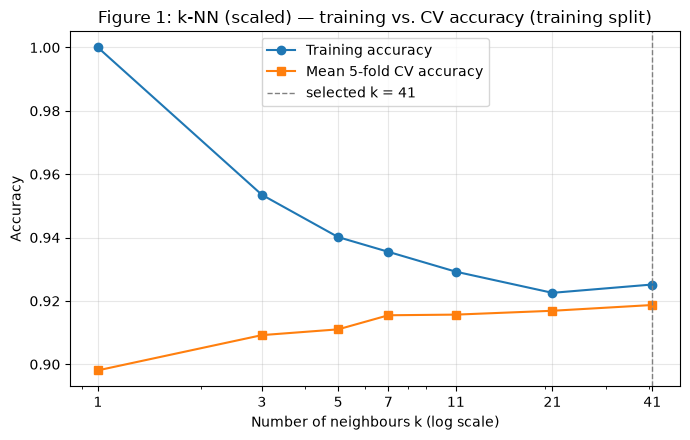

In [11]:
# Task 1.3 B — neighbourhood-size sweep with training-only stratified CV
k_values = [1, 3, 5, 7, 11, 21, 41]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

knn_rows = []
for k in k_values:
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=k))])
    cv_scores = cross_val_score(pipe, X_binary_train, y_binary_train, cv=cv, scoring="accuracy")
    pipe.fit(X_binary_train, y_binary_train)
    train_acc = accuracy_score(y_binary_train, pipe.predict(X_binary_train))
    knn_rows.append({"k": k, "train_accuracy": train_acc,
                     "mean_cv_accuracy": cv_scores.mean(), "sd_cv_accuracy": cv_scores.std(ddof=1)})

knn_sweep = pd.DataFrame(knn_rows)
display(knn_sweep.round(4))

# Highest unrounded mean CV accuracy; ties -> smallest k (rows are in increasing k)
best_idx = knn_sweep["mean_cv_accuracy"].to_numpy().argmax()
best_k = int(knn_sweep.loc[best_idx, "k"])
best_k_cv_accuracy = float(knn_sweep.loc[best_idx, "mean_cv_accuracy"])
print(f"best_k = {best_k}, best_k_cv_accuracy = {best_k_cv_accuracy:.6f}")

fig, ax = plt.subplots()
ax.plot(knn_sweep["k"], knn_sweep["train_accuracy"], "o-", label="Training accuracy")
ax.plot(knn_sweep["k"], knn_sweep["mean_cv_accuracy"], "s-", label="Mean 5-fold CV accuracy")
ax.axvline(best_k, color="grey", ls="--", lw=1, label=f"selected k = {best_k}")
ax.set_xscale("log"); ax.set_xticks(k_values); ax.set_xticklabels(k_values)
ax.set_xlabel("Number of neighbours k (log scale)"); ax.set_ylabel("Accuracy")
ax.set_title("Figure 1: k-NN (scaled) — training vs. CV accuracy (training split)")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

<span style="color: green; font-size: 20px;">**Question 1c: Distance, scaling, and model capacity**</span>

(i) Explain why a feature with a much larger numerical scale can dominate Euclidean distance. How does standardization address this? In your explanation, also discuss how fitting the scaler before the train–test split could introduce data leakage.

(ii) Using your sweep, contrast a very small and very large `k` (from the sweep provided earlier) in terms of model flexibility, bias, and variance. Use their training and mean CV accuracies to support your comparison.

(iii) Would choosing `k` by training accuracy give the same choice as choosing it by mean CV accuracy? Cite values from your sweep and explain which measure is more useful for predicting performance on unseen data.

**[5 Marks]**


**Answer:**

**(i)** Euclidean distance $\lVert x-x'\rVert=\sqrt{\sum_j (x_j-x'_j)^2}$ adds squared differences in each feature's raw units. In the training split `Area` and `ConvexArea` range over ≈38,000 pixels (SD ≈ 7,800) while `ShapeFactor2` ranges over 0.0023 and `Solidity` over 0.047. A typical difference in Area is ~10⁶–10⁷ times larger than one in ShapeFactor2, so the squared Area/ConvexArea/Perimeter terms dominate the sum and k-NN effectively becomes "nearest by size", ignoring shape ratios. Standardisation $z_j=(x_j-\hat\mu_j)/\hat\sigma_j$ puts each feature in SD units so each contributes on a comparable scale. Here it raised k=7 test accuracy from 0.9184 (raw) to 0.9289 (scaled). Leakage: if $\hat\mu_j,\hat\sigma_j$ were computed on all rows before splitting (or on all CV folds), test/validation rows would influence the preprocessing applied to training data, so the evaluation would no longer simulate truly unseen beans and could be optimistically biased. The scaler must be fitted on the training (or training-fold) rows only — hence the `Pipeline`.

**(ii)** With **k = 1** the classifier copies the label of the single nearest neighbour: a very flexible, jagged boundary with low bias but high variance. Training accuracy is 1.000 (each point is its own neighbour) but mean CV accuracy is only 0.898 — the lowest in the sweep — showing it memorises noise. With **k = 41** each prediction averages 41 neighbours, giving a smoother boundary: higher bias, much lower variance. Training accuracy drops to 0.925 but CV accuracy rises to 0.919, and the train–CV gap shrinks from 0.10 to 0.007. Over this range the extra bias of large k costs less than the variance it removes.

**(iii)** No. Training accuracy is maximised at **k = 1** (1.000) and decreases with k, whereas mean CV accuracy is maximised at **k = 41** (0.9187; k=21 gives 0.9169). Training accuracy is evaluated on the same points the model memorised, so it rewards over-fitting. CV accuracy scores each fold with a model that never saw it, so it estimates performance on new beans and is the more useful selection criterion. (The CV differences between k = 11, 21 and 41 are smaller than the fold SD ≈ 0.008, so those choices are practically similar; k = 41 is still chosen by the pre-registered rule.)

<span style="color: purple; font-size: 20px;">**Task 1.4: Trees and ensembles**</span>

**A. Decision-tree depth sweep**

Use

```python
depth_values = [1, 2, 3, 4, 5, 7, 10, None]
```

For each depth:

- fit `DecisionTreeClassifier(max_depth=depth, random_state=0)` on the full binary training split
- record training accuracy
- compute mean 5-fold stratified CV accuracy using the same `cv` from Task 1.3
- store the results in a DataFrame
- plot training accuracy and mean CV accuracy against tree depth

For plotting, `None` may be shown as `"unrestricted"`.

Select `best_depth` using the highest **unrounded mean CV accuracy**. If several depths tie, choose the shallowest one, treating `None` as deeper than every finite depth. Store the selected mean CV accuracy as `best_depth_cv_accuracy`.

**[11 Marks across parts A–B]**


,depth_label,fitted_depth,train_accuracy,mean_cv_accuracy,sd_cv_accuracy
0,1,1,0.9155,0.9134,0.0113
1,2,2,0.9155,0.9134,0.0113
2,3,3,0.9155,0.9116,0.0111
3,4,4,0.9225,0.9086,0.0136
4,5,5,0.9260,0.9090,0.0074
5,7,7,0.9385,0.9035,0.0080
6,10,10,0.9729,0.8997,0.0072
7,unrestricted,19,1.0000,0.8912,0.0057


best_depth = 1, best_depth_cv_accuracy = 0.913448


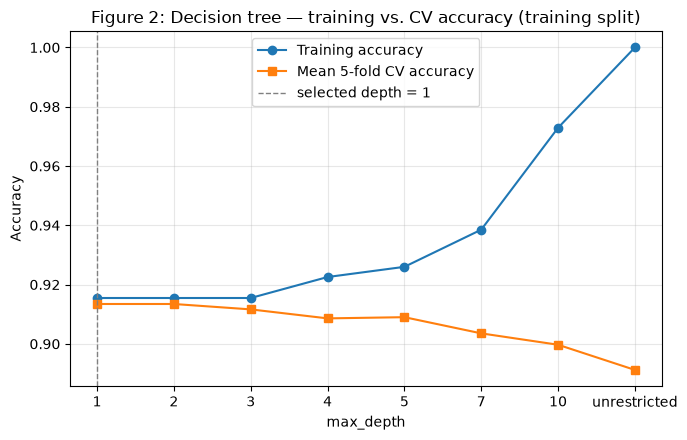

In [12]:
# Task 1.4 A — decision-tree depth sweep
depth_values = [1, 2, 3, 4, 5, 7, 10, None]

tree_rows = []
for depth in depth_values:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0)
    cv_scores = cross_val_score(tree, X_binary_train, y_binary_train, cv=cv, scoring="accuracy")
    tree.fit(X_binary_train, y_binary_train)
    tree_rows.append({"max_depth": depth,
                      "depth_label": "unrestricted" if depth is None else str(depth),
                      "fitted_depth": tree.get_depth(),
                      "train_accuracy": accuracy_score(y_binary_train, tree.predict(X_binary_train)),
                      "mean_cv_accuracy": cv_scores.mean(), "sd_cv_accuracy": cv_scores.std(ddof=1)})

tree_sweep = pd.DataFrame(tree_rows)
display(tree_sweep.drop(columns="max_depth").round(4))

# Highest unrounded mean CV accuracy; ties -> shallowest (None last, list already ordered)
best_tree_idx = tree_sweep["mean_cv_accuracy"].to_numpy().argmax()
best_depth = depth_values[best_tree_idx]
best_depth_cv_accuracy = float(tree_sweep.loc[best_tree_idx, "mean_cv_accuracy"])
print(f"best_depth = {best_depth}, best_depth_cv_accuracy = {best_depth_cv_accuracy:.6f}")

fig, ax = plt.subplots()
xpos = np.arange(len(depth_values))
ax.plot(xpos, tree_sweep["train_accuracy"], "o-", label="Training accuracy")
ax.plot(xpos, tree_sweep["mean_cv_accuracy"], "s-", label="Mean 5-fold CV accuracy")
ax.axvline(best_tree_idx, color="grey", ls="--", lw=1, label=f"selected depth = {best_depth}")
ax.set_xticks(xpos); ax.set_xticklabels(tree_sweep["depth_label"])
ax.set_xlabel("max_depth"); ax.set_ylabel("Accuracy")
ax.set_title("Figure 2: Decision tree — training vs. CV accuracy (training split)")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**B. Decision Tree vs. Random Forest vs. Gradient Boosting**

Fit the following models on the same binary training data:

```python
DecisionTreeClassifier(max_depth=best_depth, random_state=0)

RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    max_features="sqrt",
    bootstrap=True,
    random_state=0
)

GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=1.0,
    random_state=0
)
```

Use `fit_classifier(..., scale=False)` with all 16 original features. Store the returned dictionaries as `tree_result`, `rf_result`, and `gb_result`, respectively. Report train and test accuracy for all three models in one table. Use the configurations shown above without additional tuning.


In [13]:
# Task 1.4 B — selected tree vs. random forest vs. gradient boosting (no scaling)
tree_result = fit_classifier(DecisionTreeClassifier(max_depth=best_depth, random_state=0),
                             X_binary_train, y_binary_train, X_binary_test, y_binary_test, scale=False)
rf_result = fit_classifier(RandomForestClassifier(n_estimators=200, max_depth=None, max_features="sqrt",
                                                  bootstrap=True, random_state=0),
                           X_binary_train, y_binary_train, X_binary_test, y_binary_test, scale=False)
gb_result = fit_classifier(GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                                      subsample=1.0, random_state=0),
                           X_binary_train, y_binary_train, X_binary_test, y_binary_test, scale=False)

tree_compare = pd.DataFrame(
    {name: {"train_accuracy": r["train_accuracy"], "test_accuracy": r["test_accuracy"],
            "train_minus_test": r["train_accuracy"] - r["test_accuracy"],
            "test_errors": float((r["y_test_pred"] != y_binary_test.to_numpy()).sum())}
     for name, r in [(f"Decision Tree (max_depth={best_depth})", tree_result),
                     ("Random Forest (200 trees)", rf_result),
                     ("Gradient Boosting (100 stages)", gb_result)]}
).T
tree_compare.round(4)

,train_accuracy,test_accuracy,train_minus_test,test_errors
Decision Tree (max_depth=1),0.9155,0.9264,-0.0110,91.0
Random Forest (200 trees),1.0000,0.9361,0.0639,79.0
Gradient Boosting (100 stages),0.9454,0.9321,0.0133,84.0


<span style="color: green; font-size: 20px;">**Question 1d: Tree capacity and ensemble mechanisms**</span>

(i) Use your depth sweep to explain why a deep tree can overfit, how reducing maximum depth changes bias and variance, and why training accuracy alone should not select the depth.

(ii) How does a random forest differ from relying on one tree, and why is diversity among its trees useful? How does gradient boosting differ from training many trees independently?

(iii) Did either ensemble improve on your selected single tree on the held-out test set? Support your answer with the comparison table.

**[6 Marks]**


**Answer:**

**(i)** In the depth sweep, training accuracy climbs from 0.916 (depth 1–3) to 0.973 (depth 10) and 1.000 when unrestricted (depth 19), while mean CV accuracy falls from 0.913 (depth 1–2) to 0.900 (depth 10) and 0.891 (unrestricted). A deep tree keeps splitting until leaves are almost pure, so late splits isolate a handful of training beans and fit their noise; the partition is highly sensitive to the particular sample (high variance, low bias). Limiting the depth restricts the number of leaves, increasing bias (coarser boundary) but reducing variance. Choosing the depth by training accuracy would pick the unrestricted tree — the worst by CV — so the depth must be selected by CV. Notably, CV favoured a **depth-1 stump** (CV 0.9134, tied with depth 2): one threshold on a single size feature already separates the two varieties well, and every additional split mostly added variance.

**(ii)** A **random forest** averages 200 deep trees, each grown on a bootstrap resample and considering only $\sqrt{16}=4$ random features at each split. Each tree has low bias but high variance; because bootstrapping and feature subsampling make the trees' errors only partially correlated, averaging their votes cancels much of the variance (the variance of an average of $B$ trees with correlation $\rho$ is $\rho\sigma^2 + (1-\rho)\sigma^2/B$, so diversity—lower $\rho$—is what makes averaging effective). **Gradient boosting** instead builds trees **sequentially**: each shallow depth-3 tree is fitted to the residual errors (negative gradient of the log-loss) of the current ensemble and added with learning rate 0.1. Boosting mainly reduces **bias** by gradually correcting systematic mistakes, whereas the forest's independent, parallel trees mainly reduce **variance**.

**(iii)** Yes, modestly. On the common test set the selected depth-1 tree scores 0.9264 (91 errors out of 1237); the random forest scores 0.9361 (79 errors) and gradient boosting 0.9321 (84 errors). That is +1.0 and +0.6 percentage points (12 and 7 fewer errors). The forest reached 1.000 training accuracy (train–test gap 0.064) yet still generalised best of the three, consistent with averaging controlling variance; boosting has a small gap (0.013). With ≈1,237 test beans the standard error of an accuracy near 0.93 is about $\sqrt{0.93\cdot0.07/1237}\approx0.007$, so these differences are of the same order as test-split noise and should not be over-interpreted.

<span style="color: purple; font-size: 20px;">**Task 1.5: Naive Bayes and model comparison**</span>

**A. Manual prior × likelihood calculation**

For one hypothetical bean observation, we suppose the following quantities have already been estimated:

| Quantity | DERMASON | SIRA |
|---|---:|---:|
| Class prior $P(Y=c)$ | 0.57 | 0.43 |
| $p(x_1\mid Y=c)$ | 0.30 | 0.15 |
| $p(x_2\mid Y=c)$ | 0.20 | 0.40 |

Assuming conditional independence of the two features given the class:

1. Compute the unnormalized class score
   $$
   P(Y=c)\,p(x_1\mid Y=c)\,p(x_2\mid Y=c)
   $$
   for each class.
2. Predict the class with the larger score.

You are required to do this calculation directly, do not call `GaussianNB`.

**[10 Marks across parts A–C]**


In [14]:
# Task 1.5 A — manual prior x likelihood scores (no GaussianNB)
prior = {"DERMASON": 0.57, "SIRA": 0.43}
lik_x1 = {"DERMASON": 0.30, "SIRA": 0.15}
lik_x2 = {"DERMASON": 0.20, "SIRA": 0.40}

scores = {}
for c in prior:
    scores[c] = prior[c] * lik_x1[c] * lik_x2[c]
    print(f"score({c}) = {prior[c]} x {lik_x1[c]} x {lik_x2[c]} = {scores[c]:.4f}")

predicted = max(scores, key=scores.get)
total = sum(scores.values())
print(f"\nPredicted class: {predicted}")
print("Normalised posteriors (for interpretation):",
      {c: round(s / total, 4) for c, s in scores.items()})

score(DERMASON) = 0.57 x 0.3 x 0.2 = 0.0342
score(SIRA) = 0.43 x 0.15 x 0.4 = 0.0258

Predicted class: DERMASON
Normalised posteriors (for interpretation): {'DERMASON': 0.57, 'SIRA': 0.43}


**B. Gaussian Naive Bayes on the binary Dry Bean data**

Fit `GaussianNB()` with `fit_classifier` using `X_binary_train`, `y_binary_train`, `X_binary_test`, and `y_binary_test`, with `scale=False` for the original unscaled features. Save the returned dictionary as `nb_result` and report its train and test accuracy.


In [15]:
# Task 1.5 B — Gaussian Naive Bayes on unscaled binary features
nb_result = fit_classifier(GaussianNB(), X_binary_train, y_binary_train,
                           X_binary_test, y_binary_test, scale=False)
print(f"Gaussian NB  train accuracy: {nb_result['train_accuracy']:.4f}")
print(f"Gaussian NB  test accuracy:  {nb_result['test_accuracy']:.4f}")

Gaussian NB  train accuracy: 0.9015
Gaussian NB  test accuracy:  0.9216


**C. Final six-model comparison**

Fit `KNeighborsClassifier(n_neighbors=best_k)` with `fit_classifier(..., scale=True)` and store the returned dictionary as `knn_result`. Reuse the retained fitted results from the earlier tasks.

Construct one comparison table containing:

1. Logistic Regression: `logistic_result`
2. k-NN using `best_k`: `knn_result`
3. Decision Tree using `best_depth`: `tree_result`
4. Random Forest: `rf_result`
5. Gradient Boosting: `gb_result`
6. Gaussian Naive Bayes: `nb_result`

For each model, report:

- training accuracy: `train_accuracy`
- CV accuracy: `best_k_cv_accuracy` for k-NN and `best_depth_cv_accuracy` for Decision Tree
- final test accuracy: `test_accuracy`

For the four models without a tuned hyperparameter, the CV column may be left blank / `NaN`. One of Task 1.5's 10 marks is for a complete, correctly labeled six-model comparison table.


In [16]:
# Task 1.5 C — final six-model comparison
knn_result = fit_classifier(KNeighborsClassifier(n_neighbors=best_k),
                            X_binary_train, y_binary_train, X_binary_test, y_binary_test, scale=True)

model_results = [
    ("Logistic Regression (scaled)", logistic_result, np.nan),
    (f"k-NN (k={best_k}, scaled)", knn_result, best_k_cv_accuracy),
    (f"Decision Tree (max_depth={best_depth})", tree_result, best_depth_cv_accuracy),
    ("Random Forest", rf_result, np.nan),
    ("Gradient Boosting", gb_result, np.nan),
    ("Gaussian Naive Bayes", nb_result, np.nan),
]
comparison = pd.DataFrame([
    {"model": name, "train_accuracy": r["train_accuracy"], "cv_accuracy": cv_acc,
     "test_accuracy": r["test_accuracy"], "train_test_gap": r["train_accuracy"] - r["test_accuracy"]}
    for name, r, cv_acc in model_results
]).set_index("model")
print("Table 1: Six-model comparison, DERMASON (0) vs SIRA (1). Train/CV on training split; test on held-out 20% split.")
comparison.round(4)

Table 1: Six-model comparison, DERMASON (0) vs SIRA (1). Train/CV on training split; test on held-out 20% split.


,train_accuracy,cv_accuracy,test_accuracy,train_test_gap
model,,,,
Logistic Regression (scaled),0.9191,NaN,0.9361,-0.0170
"k-NN (k=41, scaled)",0.9252,0.9187,0.9337,-0.0085
Decision Tree (max_depth=1),0.9155,0.9134,0.9264,-0.0110
Random Forest,1.0000,NaN,0.9361,0.0639
Gradient Boosting,0.9454,NaN,0.9321,0.0133
Gaussian Naive Bayes,0.9015,NaN,0.9216,-0.0201


<span style="color: green; font-size: 20px;">**Question 1e: The Naive Bayes assumption**</span>

(i) What role does the **class prior** play?  
(ii) What role do the **feature likelihoods** play?  
(iii) Where does the “naive” conditional-independence assumption enter the calculation?  
(iv) In the real Dry Bean data, are measurements such as area, perimeter, and axis lengths likely to be literally independent given the class? Explain briefly.

**[3 Marks]**


**Answer:**

Manual calculation: score(DERMASON) $=0.57\times0.30\times0.20=0.0342$; score(SIRA) $=0.43\times0.15\times0.40=0.0258$, so the prediction is **DERMASON** (normalised posterior 0.0342/0.0600 = 0.57).

**(i) Prior.** $P(Y=c)$ is the base rate of each class before looking at the bean's measurements. It shifts the decision toward the more frequent class; here DERMASON's higher prior (0.57 vs 0.43) is part of why it wins.

**(ii) Likelihoods.** $p(x_j\mid Y=c)$ measures how typical the observed feature value is for beans of class $c$ (in GaussianNB, a normal density with class-specific mean and variance). They update the prior: $x_1$ favours DERMASON (0.30 vs 0.15), $x_2$ favours SIRA (0.40 vs 0.20). Their ratios exactly offset (2× each way), so the posterior equals the prior, and the prior decides.

**(iii) Naive assumption.** It enters where the joint likelihood is factorised: $p(x_1,x_2\mid Y=c)=p(x_1\mid Y=c)\,p(x_2\mid Y=c)$, i.e. multiplying per-feature likelihoods instead of modelling their joint distribution and covariance.

**(iv)** No. Area, Perimeter, ConvexArea, EquivDiameter and the axis lengths are all functions of the same bean outline. For example, EquivDiameter $=\sqrt{4\,\text{Area}/\pi}$, and Area ≈ ConvexArea. Within a variety they are therefore strongly correlated. NB effectively counts the same "size" evidence several times, which makes its probabilities overconfident (91.7% of its test probabilities are below 0.02 or above 0.98, Task 2.3). It also explains why its accuracy (0.922) trails the models that handle correlated features (≈0.93–0.94). It can still rank the classes reasonably because the double-counting often pushes in the correct direction.

---

## Task 2: Imbalance, Multiclass Classification and Calibration (25 points)


<span style="color: red; font-size: 22px;">The problem at hand:</span>

Class imbalance describes how evenly observations are distributed across classes. The class counts you saw in Task 1.1 show this imbalance for DERMASON and SIRA classes.

In this task, we create a class imbalance **only in the binary training data** and evaluate the behavior of logistic regression under the imbalance. 


<span style="color: purple; font-size: 20px;">**Task 2.1: Class imbalance**</span>


The cell below keeps all DERMASON training examples, downsamples SIRA examples to approximately **15% of the training set**, and creates `X_imbalanced_train` and `y_imbalanced_train`.

Keep the original test set unchanged.

**[5 Marks for the experiment below]**


In [17]:
# Setup: create class imbalance in training data only
X_dermason_train = X_binary_train.loc[y_binary_train.eq(0)]
X_sira_train = X_binary_train.loc[y_binary_train.eq(1)]
target_positive_fraction = 0.15
n_sira_keep = int(
    len(X_dermason_train) * target_positive_fraction / (1 - target_positive_fraction)
)
X_imbalanced_train = pd.concat([
    X_dermason_train,
    X_sira_train.sample(n=n_sira_keep, random_state=2),
]).sample(frac=1, random_state=2).copy()
y_imbalanced_train = y_binary_train.loc[X_imbalanced_train.index].copy()

print("Imbalanced training class counts:")
print(y_imbalanced_train.value_counts().sort_index())
print("Imbalanced training class proportions:")
print(y_imbalanced_train.value_counts(normalize=True).sort_index())


Imbalanced training class counts:
y
0    2836
1     500
Name: count, dtype: int64
Imbalanced training class proportions:
y
0    0.85012
1    0.14988
Name: proportion, dtype: float64


**Experiment: baseline vs. class weights vs. threshold adjustment**

Use **logistic regression only**, with `StandardScaler()` fitted on the imbalanced training data inside each pipeline. You may reuse `fit_classifier`.

1. Fit the **baseline**: `LogisticRegression(max_iter=3000, random_state=0)` on `X_imbalanced_train`, `y_imbalanced_train`
2. Fit the **class-weighted model** on the same data: `LogisticRegression(max_iter=3000, class_weight='balanced', random_state=0)`
3. Using the **same fitted baseline probabilities**, produce predictions at thresholds **0.50 and 0.30**, predict SIRA (`1`) when its probability is at least the threshold. Do not retrain for threshold adjustment

Evaluate on `X_binary_test`, `y_binary_test`. Create **one table with the following three rows**:

- baseline at threshold 0.50
- class-weighted model at threshold 0.50
- baseline at threshold 0.30

Present the accuracy and confusion-matrix counts (TN, FP, FN, TP) for all three configurations in a single comparison table. Treat SIRA as positive. `TP` counts SIRA cases detected and `FN` counts SIRA cases missed.


In [18]:
# Task 2.1 — baseline vs class weights vs threshold 0.30 (trained on imbalanced data, tested on unchanged test set)
def confusion_row(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"configuration": name, "accuracy": accuracy_score(y_true, y_pred),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "SIRA_recall": tp / (tp + fn), "SIRA_precision": tp / (tp + fp) if (tp + fp) else np.nan}

imb_base = fit_classifier(LogisticRegression(max_iter=3000, random_state=0),
                          X_imbalanced_train, y_imbalanced_train, X_binary_test, y_binary_test, scale=True)
imb_weighted = fit_classifier(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=0),
                              X_imbalanced_train, y_imbalanced_train, X_binary_test, y_binary_test, scale=True)

p_sira_base = imb_base["y_test_proba"][:, 1]          # same fitted baseline, no retraining
pred_base_050 = (p_sira_base >= 0.50).astype(int)
pred_base_030 = (p_sira_base >= 0.30).astype(int)
pred_weighted_050 = (imb_weighted["y_test_proba"][:, 1] >= 0.50).astype(int)

imbalance_table = pd.DataFrame([
    confusion_row("Baseline, threshold 0.50", y_binary_test, pred_base_050),
    confusion_row("Class-weighted (balanced), threshold 0.50", y_binary_test, pred_weighted_050),
    confusion_row("Baseline, threshold 0.30", y_binary_test, pred_base_030),
]).set_index("configuration")
print("Table 2: Logistic regression trained on the DOWNSAMPLED (~15% SIRA) training set; evaluated on the unchanged binary test set. Positive = SIRA.")
imbalance_table.round(4)

Table 2: Logistic regression trained on the DOWNSAMPLED (~15% SIRA) training set; evaluated on the unchanged binary test set. Positive = SIRA.


,accuracy,TN,FP,FN,TP,SIRA_recall,SIRA_precision
configuration,,,,,,,
"Baseline, threshold 0.50",0.9095,696,14,98,429,0.8140,0.9684
"Class-weighted (balanced), threshold 0.50",0.9297,654,56,31,496,0.9412,0.8986
"Baseline, threshold 0.30",0.9361,687,23,56,471,0.8937,0.9534


<span style="color: green; font-size: 20px;">**Question 2a: Accuracy, weights, and thresholds**</span>

(i) Why can overall accuracy be misleading when the positive class is rare? 

(ii) How did class weighting and lowering the threshold affect false positives and false negatives? Refer to your `FP`, `FN`, and accuracy values, and explain why threshold adjustment did not require retraining. Relate your observations to the precision–recall trade-off.

(iii) Conceptually, how would random oversampling differ from class weighting? Which data split should be resampled, and why? 

**[3 Marks]**


**Answer:**

**(i)** When the positive class is rare, a model can reach high accuracy by predicting the majority class most of the time. With 85% DERMASON, "always DERMASON" would already be 85% accurate on such data while detecting **no** SIRA. Accuracy weighs every error equally and is dominated by the majority class, so it hides how many minority cases are missed (FN). It also depends on the class mix of the evaluation set: our test set is still 43% SIRA, unlike the 15% training mix, so the same model could give a very different accuracy under another prevalence.

**(ii)** (Training set = **artificially downsampled** SIRA, 500 of 3336 = 15%; test set unchanged.)

| Configuration | Acc. | FP | FN | SIRA recall | SIRA precision |
|---|---:|---:|---:|---:|---:|
| Baseline, t = 0.50 | 0.910 | 14 | **98** | 0.814 | 0.968 |
| Class-weighted, t = 0.50 | 0.930 | 56 | **31** | 0.941 | 0.899 |
| Baseline, t = 0.30 | **0.936** | 23 | 56 | 0.894 | 0.953 |

Trained on 15% SIRA, the baseline learns a prior that makes it reluctant to predict SIRA, so it misses 98 of 527 SIRA beans. **Class weighting** (weights ∝ 1/class frequency) up-weights SIRA errors in the training loss, shifting the fitted intercept/boundary toward DERMASON: FN falls 98 → 31 while FP rises 14 → 56. **Lowering the threshold** to 0.30 on the *same* baseline probabilities labels more beans as SIRA: FN 98 → 56, FP 14 → 23. Threshold adjustment needs no retraining because the model's probabilities $\hat p(x)$ are unchanged; only the rule $\hat y=\mathbb 1[\hat p\ge t]$ changes. Both interventions trade **precision for recall** (moving along the precision–recall curve): more SIRA detected at the cost of more false alarms. Accuracy improved here only because the test set has many more SIRA beans (43%) than the training set; under a truly 15%-SIRA test population the extra FPs would weigh more. The right operating point depends on the relative cost of FN vs FP, not on accuracy.

**(iii)** Random oversampling duplicates (resamples with replacement) minority-class training rows until classes are balanced. Class weighting keeps the data unchanged and multiplies each minority row's loss contribution. In expectation they optimise a similar re-weighted objective. Oversampling, however, creates exact duplicates (encouraging memorisation for flexible models such as deep trees or 1-NN), adds sampling randomness, and enlarges the dataset; weighting is deterministic and cheaper. Only the **training** split (and, within CV, only the training folds) should be resampled. The test/validation sets must keep the real class distribution so metrics reflect deployment; resampling before splitting would also leak duplicated rows into the evaluation folds.

<span style="color: purple; font-size: 20px;">**Task 2.2: Multiclass strategies**</span>

We return to the original seven-class Dry Bean problem. The cell below creates `X_multiclass`, `y_multiclass`, and an 80/20 stratified train/test split with `random_state=0`.

Use this seven-class split for the experiment below.

**[5 Marks for the calculations and experiment below]**


In [19]:
# Setup: use the original dataset with all 7 classes
X_multiclass = df.loc[:, X_full.columns].copy()
y_multiclass = df['Class'].copy()

print("Number of classes:", y_multiclass.nunique())
print("Class counts:")
print(y_multiclass.value_counts())

X_multiclass_train, X_multiclass_test, y_multiclass_train, y_multiclass_test = train_test_split(
    X_multiclass, y_multiclass, test_size=0.2, stratify=y_multiclass, random_state=0
)


Number of classes: 7
Class counts:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


**Calculations and experiment: OvR vs. native multinomial logistic regression**

For $K=7$ classes, calculate the number of binary classifiers required by **OvR**, using $K$, and by **OvO**, using $K(K-1)/2$.

Using the seven-class split, fit these **two** strategies:

1. **One-vs-Rest (OvR)**
   ```python
   OneVsRestClassifier(LogisticRegression(max_iter=3000, random_state=0))
   ```
2. **Native multinomial / softmax-style logistic regression**
   ```python
   LogisticRegression(max_iter=3000, solver='lbfgs', random_state=0)
   ```

Use `StandardScaler()` before each classifier, fitted on `X_multiclass_train` only. Report train and test accuracy in one table. 


In [20]:
# Task 2.2 — OvR vs native multinomial logistic regression (7 classes)
K = y_multiclass.nunique()
n_ovr = K
n_ovo = K * (K - 1) // 2
print(f"K = {K}: OvR needs K = {n_ovr} binary classifiers; OvO needs K(K-1)/2 = {K}*{K-1}/2 = {n_ovo}.")

ovr_result = fit_classifier(OneVsRestClassifier(LogisticRegression(max_iter=3000, random_state=0)),
                            X_multiclass_train, y_multiclass_train, X_multiclass_test, y_multiclass_test, scale=True)
softmax_result = fit_classifier(LogisticRegression(max_iter=3000, solver="lbfgs", random_state=0),
                                X_multiclass_train, y_multiclass_train, X_multiclass_test, y_multiclass_test, scale=True)

multiclass_table = pd.DataFrame({
    "train_accuracy": [ovr_result["train_accuracy"], softmax_result["train_accuracy"]],
    "test_accuracy": [ovr_result["test_accuracy"], softmax_result["test_accuracy"]],
    "test_errors": [int((ovr_result["y_test_pred"] != y_multiclass_test.to_numpy()).sum()),
                    int((softmax_result["y_test_pred"] != y_multiclass_test.to_numpy()).sum())],
}, index=["One-vs-Rest logistic (7 models)", "Multinomial (softmax) logistic"])
print(f"Test set size: {len(y_multiclass_test)}")
display(multiclass_table.round(4))

# Per-class recall on the test split (supporting detail)
classes = sorted(y_multiclass.unique())
per_class = pd.DataFrame({
    "n_test": y_multiclass_test.value_counts().reindex(classes),
    "OvR_recall": [np.mean(ovr_result["y_test_pred"][y_multiclass_test.to_numpy() == c] == c) for c in classes],
    "softmax_recall": [np.mean(softmax_result["y_test_pred"][y_multiclass_test.to_numpy() == c] == c) for c in classes],
}, index=classes)
per_class.round(4)

K = 7: OvR needs K = 7 binary classifiers; OvO needs K(K-1)/2 = 7*6/2 = 21.


Test set size: 2723


,train_accuracy,test_accuracy,test_errors
One-vs-Rest logistic (7 models),0.9168,0.9174,225
Multinomial (softmax) logistic,0.9244,0.9280,196


,n_test,OvR_recall,softmax_recall
BARBUNYA,265,0.9019,0.9321
BOMBAY,104,1.0000,1.0000
CALI,326,0.9264,0.9479
DERMASON,709,0.8914,0.9111
HOROZ,386,0.9508,0.9585
SEKER,406,0.9286,0.9409
SIRA,527,0.9051,0.8899


<span style="color: green; font-size: 20px;">**Question 2b: Multiclass strategies**</span>

(i) What question does each OvR classifier learn to answer? What would each OvO classifier learn, and why does OvO require more classifiers as the number of classes grows?

(ii) How does native multinomial/softmax classification differ conceptually from OvO and OvR strategies? Why is the bean problem multiclass rather than multilabel?

(iii) How different were the two fitted strategies' test accuracies? Support your answer with the comparison table.

**[4 Marks]**


**Answer:**

For $K=7$: **OvR** needs $K=7$ binary classifiers; **OvO** needs $K(K-1)/2 = 7\cdot6/2 = 21$.

**(i)** Each **OvR** classifier answers "is this bean variety $c$, or any of the other six?" — e.g. SIRA vs {all others}. The predicted class is the one whose classifier gives the highest score. Each **OvO** classifier answers "given that the bean is either $c$ or $c'$, which one is it?", trained only on rows of those two classes, and the final label is chosen by voting. OvO needs one model per unordered pair, so the count grows quadratically, $\binom{K}{2}=K(K-1)/2$, whereas OvR grows linearly in $K$.

**(ii)** Native **multinomial (softmax)** logistic regression fits **one joint model** with a weight vector per class, $P(Y=c\mid x)=\exp(w_c^\top x+b_c)/\sum_{k}\exp(w_k^\top x+b_k)$, trained with a single cross-entropy loss. Probabilities are coupled and sum to 1 by construction. OvR and OvO instead decompose the problem into independent binary problems whose scores must be combined post hoc, and their per-model probabilities are not jointly normalised or mutually consistent. The bean problem is **multiclass, not multilabel**, because each bean has exactly one variety — the labels are mutually exclusive and exhaustive — so exactly one class should be predicted, which softmax encodes directly.

**(iii)** On the 2723-bean seven-class test split, softmax logistic regression achieved **0.9280** test accuracy (196 errors) versus **0.9174** for OvR (225 errors) — about 1.1 percentage points (29 fewer errors). Train accuracies (0.924 vs 0.917) closely match test, so neither over-fits. Per-class recall shows softmax ahead on six of seven varieties (e.g. BARBUNYA 0.93 vs 0.90, DERMASON 0.91 vs 0.89), slightly behind on SIRA (0.89 vs 0.91), with BOMBAY perfect for both. The gap is plausible given the joint training, but it comes from a single test split, so it is a moderate rather than definitive difference.

<span style="color: purple; font-size: 20px;">**Task 2.3: Probability calibration with Platt scaling**</span>

The probability attached to a classification decision is useful only when its numerical value can be interpreted as a frequency of similar outcomes. A classifier can have high accuracy yet produce overconfident probabilities. **Platt scaling** fits a sigmoid mapping from classifier scores to observed class frequencies; it changes probability estimates, not the original class labels used for training.

**Experiment (2 marks).** Return to the **original, non-downsampled DERMASON/SIRA training split** (`X_binary_train`, `y_binary_train`). Treat **SIRA = 1** as positive. Use **Gaussian Naive Bayes** as a fixed base estimator (do not pick the model based on test performance). Compare:

1. An uncalibrated `GaussianNB()` fitted on the binary training set.
2. `CalibratedClassifierCV(estimator=GaussianNB(), method='sigmoid', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0))`, fitted on that same training split. This uses out-of-fold calibration within the training data.

Predict probabilities on the **same unchanged binary test set**. Compute the Brier score and accuracy at threshold 0.50 for both models. Produce **Figure C1: Reliability diagram**, displaying observed fraction of SIRA versus mean predicted probability for both models (8 bins) alongside the perfect-calibration diagonal. Include a small results table. Use `calibration_curve` or `CalibrationDisplay` from `sklearn.calibration`. **Do not fit a sigmoid or any other transformation on test labels.** The calibration method and base estimator are fixed by this question; do not use test metrics to tune them.

**Hint:** `brier_score_loss(y_true, p)` uses probabilities `p` for class 1. The Brier score is a *probability-quality metric*; it is not the same as classification accuracy.


Table 3: Calibration comparison on the unchanged binary test set (positive = SIRA).


,Brier_score,accuracy_t0.50,share_p<0.02_or_>0.98
GaussianNB (uncalibrated),0.0699,0.9216,0.9167
"GaussianNB + Platt (sigmoid, 5-fold CV)",0.0659,0.9224,0.0000


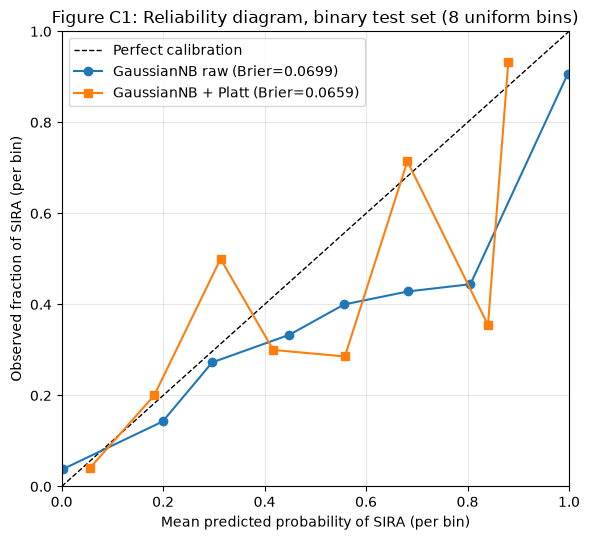

In [21]:
# TASK 2.3 — YOUR CODE: Platt scaling and reliability diagram (C1)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

calibration_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# TODO 1: Fit GaussianNB() using X_binary_train, y_binary_train.
raw_nb = GaussianNB().fit(X_binary_train, y_binary_train)

# TODO 2: Construct and fit CalibratedClassifierCV with method='sigmoid',
# cv=calibration_cv, and GaussianNB() as the estimator.
platt_nb = CalibratedClassifierCV(estimator=GaussianNB(), method="sigmoid", cv=calibration_cv)
platt_nb.fit(X_binary_train, y_binary_train)       # sigmoid fitted on out-of-fold TRAINING predictions only

# TODO 3: Compute P(SIRA=1) for BOTH on X_binary_test.
p_raw = raw_nb.predict_proba(X_binary_test)[:, 1]
p_platt = platt_nb.predict_proba(X_binary_test)[:, 1]

# TODO 4: Report Brier score and accuracy (threshold=0.50) in one table.
calibration_table = pd.DataFrame({
    "Brier_score": [brier_score_loss(y_binary_test, p_raw), brier_score_loss(y_binary_test, p_platt)],
    "accuracy_t0.50": [accuracy_score(y_binary_test, (p_raw >= 0.5).astype(int)),
                       accuracy_score(y_binary_test, (p_platt >= 0.5).astype(int))],
    "share_p<0.02_or_>0.98": [np.mean((p_raw < .02) | (p_raw > .98)), np.mean((p_platt < .02) | (p_platt > .98))],
}, index=["GaussianNB (uncalibrated)", "GaussianNB + Platt (sigmoid, 5-fold CV)"])
print("Table 3: Calibration comparison on the unchanged binary test set (positive = SIRA).")
display(calibration_table.round(4))

# TODO 5: Plot empirical fraction of positives vs. predicted probabilities
#         for both models, using 8 bins, plus the ideal diagonal; label axes.
frac_raw, mean_raw = calibration_curve(y_binary_test, p_raw, n_bins=8)
frac_platt, mean_platt = calibration_curve(y_binary_test, p_platt, n_bins=8)

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.plot(mean_raw, frac_raw, "o-", label=f"GaussianNB raw (Brier={calibration_table.iloc[0,0]:.4f})")
ax.plot(mean_platt, frac_platt, "s-", label=f"GaussianNB + Platt (Brier={calibration_table.iloc[1,0]:.4f})")
ax.set_xlabel("Mean predicted probability of SIRA (per bin)")
ax.set_ylabel("Observed fraction of SIRA (per bin)")
ax.set_title("Figure C1: Reliability diagram, binary test set (8 uniform bins)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# Keep C1 and the metrics for your report.

<span style="color: green; font-size: 20px;">**Question 2c: Calibration is not classification accuracy**</span>

**(i)** In 1–2 sentences, distinguish a correctly classified label from a well-calibrated probability. Define what it means for observations assigned probability 0.8 to be calibrated.

**(ii)** From your Brier scores and reliability plot **C1**, state whether sigmoid calibration helped on this test split. Could it improve probability quality without improving accuracy at threshold 0.50? If it performed worse, why does that not invalidate the method?

**(iii)** Explain why fitting the calibration mapping on test labels, or fitting a calibration map in advance using all training and test examples, would invalidate your evaluation.

**[2 Marks]**

**Answer (Question 2c):**

| Model (fit on original binary training split) | Brier (test) ↓ | Accuracy t = 0.50 (test) |
|---|---:|---:|
| GaussianNB, uncalibrated | 0.0699 | 0.9216 |
| GaussianNB + Platt sigmoid (5-fold, training-only) | **0.0659** | 0.9224 |

**(i)** A correctly classified label means only that the thresholded decision matched the true class. A well-calibrated probability means the *number itself* is right in frequency terms: among all beans to which the model assigns $P(\text{SIRA})=0.8$, about 80% are actually SIRA ($P(Y=1\mid\hat p(X)=0.8)=0.8$). A model can be accurate yet badly calibrated (e.g. it outputs 0.999 for beans that are SIRA only 85% of the time).

**(ii)** Yes — on this test split sigmoid calibration lowered the Brier score from 0.0699 to 0.0659 (≈6% better). Accuracy changed by just one bean (0.9216 → 0.9224). In C1 the raw NB curve is far from the diagonal because GaussianNB pushes 91.7% of its probabilities below 0.02 or above 0.98 (a consequence of double-counting correlated size features). Its extreme bins therefore contain mistakes made with near-certainty, and the middle bins are almost empty. After Platt scaling no probability is that extreme (0% outside [0.02, 0.98]), and the points lie closer to the diagonal. So calibration can improve probability quality with almost no change in accuracy: the sigmoid is monotone, so it preserves the ranking of beans and changes the 0.5-threshold decision only for beans whose probabilities cross 0.5. Had it performed worse, that would not invalidate the method: the gain depends on the base model's distortion being sigmoid-shaped, on how much training data the 5 folds leave for fitting the two Platt parameters, and on random variation in a single 1237-bean test split. The method is judged by a fair, pre-specified protocol, not by one realisation.

**(iii)** The test set exists to estimate performance on beans the whole procedure never saw. Fitting the sigmoid on test labels (or fitting the calibration map on train + test together) uses those labels to shape the predictions being scored, which is **leakage**. The resulting Brier score and reliability curve would be optimistically biased (the map is tuned to the very errors it is graded on) and would no longer estimate deployment performance. Calibration must be learned from training data only, here via out-of-fold predictions within the training split, so that the test set remains an independent check.

<span style="color: purple; font-size: 20px;">**Task 2.4: Final Model Choice and Classification Model Card**</span>

Write a **3–6 sentence model-selection recommendation**, then provide a **concise classification model card** for the binary model you choose, based on your own results:

1. From the six-model binary comparison in Task 1.5, choose one classifier for DERMASON vs. SIRA. Justify the choice using its **test accuracy, train–test gap, and preprocessing requirements**.
2. Your six-model ranking uses one test split. Suppose your selected model outperforms another model by a small margin on the test set. How would you determine whether this difference reflects a reliable performance advantage?
3. What did the imbalance experiment reveal about relying on accuracy alone, and what would you check before using the classifier on beans from a different camera, lighting setup, or growing region? Discuss data representativeness, potential distribution shift, and the importance of external validation under the intended deployment conditions.

**Classification Model Card (required; included in the 4 marks):** Use the structured fields in the assignment guide: model name/type and outcome, data and features, training and preprocessing, quantitative evaluation (including errors under imbalance and calibration evidence if applicable), subgroup/class observations, intended and inappropriate uses, known limitations, and safeguards/monitoring. Distinguish evidence you measured from possible deployment risks. You do **not** have to build a separate model card for the seven-class experiment. Do not claim performance on unseen cameras or geographical regions without external data.

**[4 Marks: 2 for justified model selection and 2 for the model card]**


Table 4: Chosen model (scaled logistic regression) on the binary test set; trained on the original training split.


,value
train_accuracy,0.9191
test_accuracy,0.9361
TN,669.0000
FP (DERMASON called SIRA),41.0000
FN (SIRA called DERMASON),38.0000
TP,489.0000
DERMASON recall,0.9423
SIRA recall,0.9279
SIRA precision,0.9226
Brier score (test),0.0483


Training-split 5-fold CV accuracy: LR 0.9175 ± 0.0086; RF 0.9189 ± 0.0075
Test cases LR right / RF wrong: 29;  LR wrong / RF right: 29


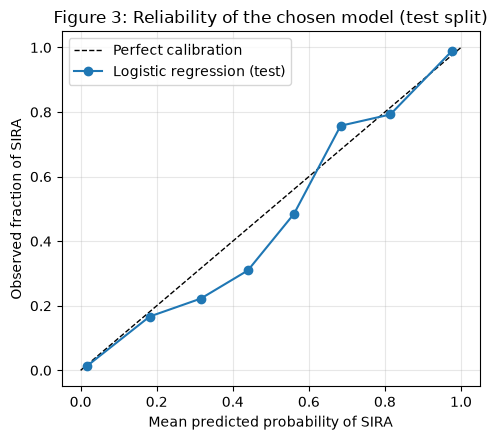

In [22]:
# Task 2.4 — evidence for the chosen model (scaled logistic regression, original balanced-ish training split)
from sklearn.metrics import brier_score_loss, precision_score, recall_score
y_true_test = y_binary_test.to_numpy()
lr_pred = logistic_result["y_test_pred"]
lr_proba = logistic_result["y_test_proba"][:, 1]
tn, fp, fn, tp = confusion_matrix(y_true_test, lr_pred, labels=[0, 1]).ravel()
lr_card = pd.Series({
    "train_accuracy": logistic_result["train_accuracy"],
    "test_accuracy": logistic_result["test_accuracy"],
    "TN": tn, "FP (DERMASON called SIRA)": fp, "FN (SIRA called DERMASON)": fn, "TP": tp,
    "DERMASON recall": tn / (tn + fp), "SIRA recall": tp / (tp + fn),
    "SIRA precision": precision_score(y_true_test, lr_pred),
    "Brier score (test)": brier_score_loss(y_true_test, lr_proba),
})
print("Table 4: Chosen model (scaled logistic regression) on the binary test set; trained on the original training split.")
display(lr_card.round(4).to_frame("value"))

# 5-fold CV accuracy on training split for the two top-tied models (training data only, for the uncertainty discussion)
lr_cv = cross_val_score(Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=3000, random_state=0))]),
                        X_binary_train, y_binary_train, cv=cv)
rf_cv = cross_val_score(RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=0),
                        X_binary_train, y_binary_train, cv=cv)
print(f"Training-split 5-fold CV accuracy: LR {lr_cv.mean():.4f} ± {lr_cv.std(ddof=1):.4f}; RF {rf_cv.mean():.4f} ± {rf_cv.std(ddof=1):.4f}")

# Disagreement between LR and RF on the test set (basis for a paired McNemar-style check)
rf_pred = rf_result["y_test_pred"]
b = int(np.sum((lr_pred == y_true_test) & (rf_pred != y_true_test)))
c = int(np.sum((lr_pred != y_true_test) & (rf_pred == y_true_test)))
print(f"Test cases LR right / RF wrong: {b};  LR wrong / RF right: {c}")

frac_lr, mean_lr = calibration_curve(y_true_test, lr_proba, n_bins=8)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.plot(mean_lr, frac_lr, "o-", label="Logistic regression (test)")
ax.set_xlabel("Mean predicted probability of SIRA"); ax.set_ylabel("Observed fraction of SIRA")
ax.set_title("Figure 3: Reliability of the chosen model (test split)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Answer (Task 2.4): Model recommendation**

I recommend **scaled logistic regression** for DERMASON vs SIRA. It ties for the best test accuracy (**0.9361**, 79 errors out of 1237, same as the random forest). It shows no sign of over-fitting: train 0.9191 vs test 0.9361 (gap −0.017), compared with the forest's 1.000 vs 0.936 (gap +0.064). It needs only a `StandardScaler` fitted inside the pipeline, has 17 parameters instead of 200 deep trees, and outputs reasonably calibrated probabilities (test Brier 0.048). Its edge over k-NN (0.934), gradient boosting (0.932), the depth-1 tree (0.926) and NB (0.922) is only 0.2–1.5 points, of the same order as the ≈0.007 standard error of a 1237-bean test accuracy, and on training-split 5-fold CV LR (0.9175 ± 0.0086) and RF (0.9189 ± 0.0075) are statistically indistinguishable. To decide whether a small margin is reliable, compare the models on the **same** test beans with a paired test (McNemar: here LR-right/RF-wrong = 29 and LR-wrong/RF-right = 29, i.e. no evidence of a difference), and use repeated or nested stratified CV / bootstrap confidence intervals of the accuracy difference, rather than a single split. The imbalance experiment showed that accuracy alone hides a lopsided error profile: with 15% SIRA in training the baseline missed 98 SIRA beans while still scoring 0.91. Before deployment I would check class-specific recall/precision and the operating threshold at the expected class prevalence. Before using the model on beans from a different camera, lighting set-up or growing region, I would verify that the feature distributions (especially pixel-based size features, which depend on camera resolution/distance) match the training data, collect a labelled external sample from the target setting, and re-validate (and if needed recalibrate or retrain) there.

---

### Classification Model Card — DERMASON vs SIRA logistic regression

| Field | Content |
|---|---|
| **Model overview** | Scaled binary logistic regression, `Pipeline(StandardScaler, LogisticRegression(max_iter=3000, random_state=0))`, L2 penalty C = 1 (sklearn default). Output: $P(\text{SIRA}\mid x)$ and a class label at threshold 0.50 (1 = SIRA, 0 = DERMASON). Intended decision: sort/flag dry beans of these two varieties from image-derived shape measurements. |
| **Data** | UCI Dry Bean dataset (Koklu & Ozkan; DOI 10.24432/C50S4B). Unit: one bean image. Only DERMASON (3546) and SIRA (2636) rows used, N = 6182. Features: the 16 numeric shape/size measurements; no missing values. |
| **Training & preprocessing** | Stratified 80/20 split, `random_state=0`: 4945 training, 1237 test beans. Standardisation fitted on training data only, inside the pipeline. No hyperparameter tuning; the test set was used only for the final comparison. |
| **Evaluation (test split)** | Accuracy 0.9361 (train 0.9191; 5-fold CV on train 0.9175 ± 0.0086). Confusion counts: TN 669, FP 41, FN 38, TP 489. DERMASON recall 0.942, SIRA recall 0.928, SIRA precision 0.923. Brier score 0.048 and a reliability curve close to the diagonal (Figure 3), so no extra calibration step was applied. |
| **Class-level / imbalance observations** | Errors are roughly symmetric across the two classes on the original ~57/43 mix. When SIRA was **artificially downsampled** to 15% of training, the same model type missed 98 of 527 SIRA beans at t = 0.50 (recall 0.81); class weighting (FN 31) or threshold 0.30 (FN 56) recovered recall at the cost of more false positives. Performance therefore depends on the training class mix and the threshold. |
| **Intended uses** | Decision support for separating DERMASON from SIRA beans imaged with the same acquisition system and similar conditions as the UCI data, with probabilities used for ranking or for routing uncertain beans (p near 0.5) to manual inspection. |
| **Inappropriate uses** | Classifying the other five varieties or unknown varieties (the model always outputs one of two classes); beans from different cameras, lighting, resolutions or growing regions without re-validation; fully automated decisions with financial or regulatory consequences without human review. |
| **Known limitations** | One dataset and one test split; no external validation. Size features are in pixels and depend on camera set-up, so they are vulnerable to distribution shift. The class prevalence in deployment is unknown. Correlated features make individual coefficients hard to interpret. No information about growing region, season or acquisition device is available, so subgroup performance across these was **not evaluated**. |
| **Responsible use & monitoring** | Monitor input feature distributions (e.g. mean Area, Perimeter) and predicted-SIRA rate for drift; periodically audit a labelled sample to track class-specific recall/precision and calibration. Choose the threshold from the actual cost of FN vs FP at the deployment prevalence. Before deployment in a new setting, collect labelled beans from that camera/region and re-validate, recalibrating or retraining if performance drops. |

### Suggested reading for Tasks 1–2

**Task 1 (one review):** S. B. Kotsiantis, *Supervised Machine Learning: A Review of Classification Techniques*, *Informatica* 31(3), 2007: https://www.informatica.si/index.php/informatica/article/view/148.

**Task 2 (one paper):** A. Niculescu-Mizil and R. Caruana, *Predicting Good Probabilities with Supervised Learning*, ICML 2005: https://icml.cc/Conferences/2005/proceedings/papers/079_GoodProbabilities_NiculescuMizilCaruana.pdf.
